# **ConvNeXtTiny**

A partir del estudio de búsqueda de hiperparámetros (`OPT-CVNXT`), se seleccionan los 3 trials con menor `val_loss` entre los completados, y se reentrena cada configuración bajo el nombre `CVNXT-1`, `CVNXT-2` y `CVNXT-3`. El entrenamiento sigue el protocolo **LP-FT**: primero se entrena solo la cabeza con el backbone congelado (Linear Probing) con un learning rate fijo, y luego se descongelan los bloques superiores seleccionados y se continúa entrenando con el learning rate de fine-tuning encontrado por Optuna para ese trial. Los resultados se evalúan sobre el conjunto de test para seleccionar el modelo final de esta arquitectura para la Fase 2.

In [1]:
# Librerías
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import gc
import csv
import json
import time
import random
import subprocess
import numpy as np
import pandas as pd
import psutil
import pynvml
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

In [2]:
# Verificar GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.set_logical_device_configuration(
        gpus[0],
        [tf.config.LogicalDeviceConfiguration(memory_limit=15360)]
    )
    print(f'GPU encontrada: {gpus[0].name} (límite 15GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

GPU encontrada: /physical_device:GPU:0 (límite 15GB)


### **Configuración**

In [3]:
# --- PATHS ---
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
DATA_PATH   = Path.home() / 'pfc' / 'Dataset Sintetico 352x192'
MODELS_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 1' / 'ConvNeXtTiny'
MODELS_PATH.mkdir(parents=True, exist_ok=True)

In [4]:
# --- CONFIGURACIÓN GENERAL ---
ARQUITECTURA  = 'ConvNeXtTiny'
DATASET       = 'Sintético'
OPTUNA_RUN_ID = 'OPT-CVNXT'
NUM_CLASSES   = 5
CLASSES       = ['CD', 'HYP', 'MI', 'NORM', 'STTC']
CHANNELS      = 3   # ConvNeXtTiny recibe imágenes RGB

# Imagen
IMG_HEIGHT = 192
IMG_WIDTH  = 352
BATCH_SIZE = 32
SEED       = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

# Protocolo LP-FT (mismos valores que OPT-CVNXT)
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCH_MAX     = 100
LP_EPOCHS     = 10
WEIGHT_DECAY  = 1e-2
LP_LR         = 1e-3   # LR fijo para la fase LP (igual que en OPT-CVNXT)

# Callbacks (mismos valores que OPT-CVNXT)
ES_PATIENCE   = 8
ES_MIN_DELTA  = 0.0001
RLR_FACTOR    = 0.5
RLR_PATIENCE  = 5
RLR_MIN_DELTA = 0.0001
RLR_MIN_LR    = 1e-7

In [5]:
# --- Bloques a descongelar en fase FT, por opción de ft_blocks ---
FINE_TUNE_BLOCKS = {
    1: ['convnext_tiny_stage_3_block_2'],
    2: ['convnext_tiny_stage_3_block_1', 'convnext_tiny_stage_3_block_2'],
}

def set_fine_tune_layers(backbone, ft_blocks):
    prefixes = [b + '_' for b in FINE_TUNE_BLOCKS[ft_blocks]]
    for layer in backbone.layers:
        layer.trainable = any(layer.name.startswith(p) for p in prefixes)

for n, prefixes in FINE_TUNE_BLOCKS.items():
    print(f'ft_blocks={n}: {prefixes}')

ft_blocks=1: ['convnext_tiny_stage_3_block_2']
ft_blocks=2: ['convnext_tiny_stage_3_block_1', 'convnext_tiny_stage_3_block_2']


### **Selección de los Top-3 Modelos**

Se cargan los resultados del estudio Optuna (`OPT-CVNXT.csv`) y se seleccionan los 3 trials completados con menor `val_loss` de la fase FT.

In [6]:
# --- Top-3 trials de Optuna ---
df_opt      = pd.read_csv(MODELS_PATH / f'{OPTUNA_RUN_ID}.csv', index_col='trial')
df_complete = df_opt[df_opt['state'] == 'COMPLETE'].copy()
top3        = df_complete.sort_values('value').head(3)

CONFIGS = []
for rank, (trial_num, row) in enumerate(top3.iterrows(), start=1):
    CONFIGS.append({
        'run_id':           f'CVNXT-{rank}',
        'optuna_trial':     int(trial_num),
        'optuna_val_loss':  float(row['value']),
        'epochs_optuna':    int(row['epochs_trained']),
        'dense_units':      int(row['dense_units']),
        'ft_blocks':        int(row['ft_blocks']),
        'learning_rate_ft': float(row['learning_rate_ft']),
    })

In [7]:
for cfg in CONFIGS:
    prefixes = FINE_TUNE_BLOCKS[cfg['ft_blocks']]
    print(f"{cfg['run_id']}  (trial Optuna #{cfg['optuna_trial']} - val_loss FT: {cfg['optuna_val_loss']:.4f}, {cfg['epochs_optuna']} épocas totales)")
    print(f"  dense_units      : {cfg['dense_units']}")
    print(f"  ft_blocks        : {cfg['ft_blocks']} ({prefixes})")
    print(f"  learning_rate_lp : {LP_LR:.2e}  (fijo)")
    print(f"  learning_rate_ft : {cfg['learning_rate_ft']:.2e}")
    print(f"  weight_decay     : {WEIGHT_DECAY}")
    print()

CVNXT-1  (trial Optuna #18 - val_loss FT: 0.7671, 43 épocas totales)
  dense_units      : 256
  ft_blocks        : 2 (['convnext_tiny_stage_3_block_1', 'convnext_tiny_stage_3_block_2'])
  learning_rate_lp : 1.00e-03  (fijo)
  learning_rate_ft : 1.31e-05
  weight_decay     : 0.01

CVNXT-2  (trial Optuna #17 - val_loss FT: 0.7684, 43 épocas totales)
  dense_units      : 256
  ft_blocks        : 2 (['convnext_tiny_stage_3_block_1', 'convnext_tiny_stage_3_block_2'])
  learning_rate_lp : 1.00e-03  (fijo)
  learning_rate_ft : 1.38e-05
  weight_decay     : 0.01

CVNXT-3  (trial Optuna #20 - val_loss FT: 0.7689, 43 épocas totales)
  dense_units      : 256
  ft_blocks        : 2 (['convnext_tiny_stage_3_block_1', 'convnext_tiny_stage_3_block_2'])
  learning_rate_lp : 1.00e-03  (fijo)
  learning_rate_ft : 1.35e-05
  weight_decay     : 0.01



### **Carga de Datos**

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(directory, shuffle):
    ds = tf.keras.utils.image_dataset_from_directory(
        directory,
        image_size  = (IMG_HEIGHT, IMG_WIDTH),
        color_mode  = 'grayscale',
        class_names = CLASSES,
        batch_size  = BATCH_SIZE,
        shuffle     = shuffle,
        seed        = SEED if shuffle else None,
        label_mode  = 'int',
    )
    def preprocess(x, y):
        x = tf.repeat(x, 3, axis=-1)   # Grayscale → RGB
        # ConvNeXtTiny normaliza internamente (include_preprocessing=True)
        return x, y
    return (
        ds.map(preprocess, num_parallel_calls=AUTOTUNE)
          .prefetch(AUTOTUNE)
    )

# NOTA: train_data y val_data se recrean dentro del loop de entrenamiento, una vez por run_id,
# evita arrastrar estado de shuffle entre runs.
test_data = make_dataset(DATA_PATH / 'test', shuffle=False)

print('Clases:', CLASSES)

Found 10258 files belonging to 5 classes.
Clases: ['CD', 'HYP', 'MI', 'NORM', 'STTC']


### **Arquitectura**

In [9]:
def build_convnexttiny(dense_units, input_shape=(192, 352, 3), num_classes=5):
    inputs = tf.keras.Input(shape=input_shape)

    base = tf.keras.applications.ConvNeXtTiny(
        include_top           = False,
        weights               = 'imagenet',
        input_shape           = input_shape,
        include_preprocessing = True,   # normalización ImageNet interna
    )
    base.trainable = False

    # training=False: deshabilita stochastic depth y mantiene LayerNorm en modo inferencia
    x = base(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)

    return tf.keras.Model(inputs=inputs, outputs=x, name='ConvNeXtTiny_FT'), base

### **Monitoreo de Recursos y Logging**

In [10]:
def _append_csv(filepath, row):
    filepath  = Path(filepath)
    write_hdr = not filepath.exists()
    with open(filepath, 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=row.keys())
        if write_hdr:
            w.writeheader()
        w.writerow(row)

try:
    pynvml.nvmlInit()
    _GPU_HANDLE    = pynvml.nvmlDeviceGetHandleByIndex(0)
    _GPU_AVAILABLE = True
except Exception:
    _GPU_AVAILABLE = False

class ResourceMonitor(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.ram_max   = 0.0
        self.vram_max  = 0.0
        self.gpu_utils = []
        self._pid      = os.getpid()

    def on_epoch_end(self, epoch, logs=None):
        self.ram_max = max(self.ram_max, psutil.Process().memory_info().rss / 1e9)
        if _GPU_AVAILABLE:
            for proc in pynvml.nvmlDeviceGetComputeRunningProcesses(_GPU_HANDLE):
                if proc.pid == self._pid:
                    self.vram_max = max(self.vram_max, proc.usedGpuMemory / 1e9)
                    break
            try:
                for u in pynvml.nvmlDeviceGetProcessUtilization(_GPU_HANDLE, 1000000):
                    if u.pid == self._pid:
                        self.gpu_utils.append(u.smUtil)
                        break
            except Exception:
                self.gpu_utils.append(pynvml.nvmlDeviceGetUtilizationRates(_GPU_HANDLE).gpu)


def log_training(cfg, history_lp, history_ft, monitor, t_start, t_end, model_path, lp_history_path, ft_history_path):
    prefixes = FINE_TUNE_BLOCKS[cfg['ft_blocks']]
    row = {
        'run_id':           cfg['run_id'],
        'fecha':            datetime.now().strftime('%d/%m/%Y'),
        'arquitectura':     ARQUITECTURA,
        'dataset':          DATASET,
        'img_width':        IMG_WIDTH,
        'img_height':       IMG_HEIGHT,
        'batch_size':       BATCH_SIZE,
        'seed':             SEED,
        'optuna_run_id':    f"{OPTUNA_RUN_ID}_trial{cfg['optuna_trial']}",
        'dense_units':      cfg['dense_units'],
        'ft_blocks':        cfg['ft_blocks'],
        'ft_prefixes':      ', '.join(prefixes),
        'weight_decay':     WEIGHT_DECAY,
        'learning_rate_lp': LP_LR,
        'learning_rate_ft': cfg['learning_rate_ft'],
        'loss_function':    LOSS_FUNCTION,
        'lp_epochs':        LP_EPOCHS,
        'epochs_ft':        len(history_ft.history['val_loss']),
        'es_patience':      ES_PATIENCE,
        'es_min_delta':     ES_MIN_DELTA,
        'rlr_factor':       RLR_FACTOR,
        'rlr_patience':     RLR_PATIENCE,
        'rlr_min_delta':    RLR_MIN_DELTA,
        'rlr_min_lr':       RLR_MIN_LR,
        'epochs_max':       EPOCH_MAX,
        't_start':          datetime.fromtimestamp(t_start).strftime('%d/%m - %H:%M:%S'),
        't_end':            datetime.fromtimestamp(t_end).strftime('%d/%m - %H:%M:%S'),
        't_training':       round((t_end - t_start) / 60, 2),
        'ram_max_gb':       round(monitor.ram_max, 2),
        'vram_max_gb':      round(monitor.vram_max, 2),
        'gpu_avg':          round(float(np.mean(monitor.gpu_utils)), 1) if monitor.gpu_utils else None,
        'model_path':       str(model_path.relative_to(REPO_ROOT)),
        'lp_history_path':  str(lp_history_path.relative_to(REPO_ROOT)),
        'ft_history_path':  str(ft_history_path.relative_to(REPO_ROOT)),
    }
    _append_csv(MODELS_PATH / 'CVNXT_training.csv', row)
    print(f"  CVNXT_training.csv actualizado - {cfg['run_id']}")


def log_results(run_id, y_true, y_pred, history_ft, test_loss, test_acc, classes, notas=''):
    best_epoch  = int(np.argmin(history_ft['val_loss']))
    report_dict = classification_report(y_true, y_pred, target_names=classes, output_dict=True)
    row = {
        'run_id':        run_id,
        'best_epoch_ft': best_epoch + 1,
        'best_val_loss': round(history_ft['val_loss'][best_epoch], 4),
        'best_val_acc':  round(history_ft['val_accuracy'][best_epoch], 4),
        'test_loss':     round(test_loss, 4),
        'test_acc':      round(test_acc, 4),
        'balanced_acc':  round(balanced_accuracy_score(y_true, y_pred), 4),
        'macro_f1':      round(report_dict['macro avg']['f1-score'], 4),
        'weighted_f1':   round(report_dict['weighted avg']['f1-score'], 4),
    }
    for cls in classes:
        row[f'precision_{cls}'] = round(report_dict[cls]['precision'], 4)
        row[f'recall_{cls}']    = round(report_dict[cls]['recall'],    4)
        row[f'f1_{cls}']        = round(report_dict[cls]['f1-score'],  4)
        row[f'support_{cls}']   = int(report_dict[cls]['support'])
    row['notas'] = notas
    _append_csv(MODELS_PATH / 'CVNXT_results.csv', row)
    print(f'  CVNXT_results.csv actualizado - {run_id}')
    return row

### **Entrenamiento**

Para cada configuración se aplica el protocolo LP-FT:
- **Fase LP** (`LP_EPOCHS=10` épocas): backbone congelado, solo se entrena la cabeza con `AdamW(LP_LR)` - LR fijo, igual para los 3 runs.
- **Fase FT** (hasta `EPOCH_MAX=100` épocas con EarlyStopping): se descongelan los bloques indicados por `ft_blocks` y se continúa con `AdamW(learning_rate_ft)`, el LR encontrado por Optuna para ese trial. El backbone corre siempre con `training=False`.

In [11]:
# --- ENTRENAMIENTO LP-FT ---
HISTORIES_LP = {}
HISTORIES_FT = {}

for cfg in CONFIGS:
    run_id = cfg['run_id']
    print(f'\n{"="*60}\nEntrenando {run_id} (trial Optuna #{cfg["optuna_trial"]})\n{"="*60}')

    tf.keras.backend.clear_session()
    gc.collect()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    # --- Dataset fresco para este run ---
    train_data = make_dataset(DATA_PATH / 'train', shuffle=True)
    val_data   = make_dataset(DATA_PATH / 'val',   shuffle=False)

    model, base = build_convnexttiny(
        dense_units = cfg['dense_units'],
        input_shape = (IMG_HEIGHT, IMG_WIDTH, CHANNELS),
        num_classes = NUM_CLASSES,
    )

    checkpoint_path  = MODELS_PATH / f'{run_id}.keras'
    lp_history_path  = MODELS_PATH / f'{run_id}_history_lp.json'
    ft_history_path  = MODELS_PATH / f'{run_id}_history_ft.json'
    resource_monitor = ResourceMonitor()

    # --- Fase 1: Linear Probing ---
    print(f'  Fase LP - {LP_EPOCHS} épocas (backbone congelado), lr={LP_LR:.2e}...')
    model.compile(
        optimizer = tf.keras.optimizers.AdamW(
            learning_rate = LP_LR,
            weight_decay  = WEIGHT_DECAY,
        ),
        loss    = LOSS_FUNCTION,
        metrics = ['accuracy'],
    )

    t_start    = time.time()
    history_lp = model.fit(
        train_data,
        validation_data = val_data,
        epochs          = LP_EPOCHS,
        callbacks       = [resource_monitor],
        verbose         = 1,
    )

    with open(lp_history_path, 'w') as f:
        json.dump(history_lp.history, f)
    HISTORIES_LP[run_id] = history_lp.history

    # --- Fase 2: Fine-Tuning ---
    set_fine_tune_layers(base, cfg['ft_blocks'])

    print(f'  Fase FT - ft_blocks={cfg["ft_blocks"]} ({FINE_TUNE_BLOCKS[cfg["ft_blocks"]]}), lr={cfg["learning_rate_ft"]:.2e}...')
    model.compile(
        optimizer = tf.keras.optimizers.AdamW(
            learning_rate = cfg['learning_rate_ft'],
            weight_decay  = WEIGHT_DECAY,
        ),
        loss    = LOSS_FUNCTION,
        metrics = ['accuracy'],
    )

    callbacks_ft = [
        EarlyStopping(
            monitor              = 'val_loss',
            patience             = ES_PATIENCE,
            min_delta            = ES_MIN_DELTA,
            restore_best_weights = True,
        ),
        ReduceLROnPlateau(
            monitor   = 'val_loss',
            factor    = RLR_FACTOR,
            patience  = RLR_PATIENCE,
            min_delta = RLR_MIN_DELTA,
            min_lr    = RLR_MIN_LR,
        ),
        ModelCheckpoint(
            filepath       = checkpoint_path,
            monitor        = 'val_loss',
            save_best_only = True,
            verbose        = 1,
        ),
        resource_monitor,
    ]

    history_ft = model.fit(
        train_data,
        validation_data = val_data,
        epochs          = EPOCH_MAX,
        callbacks       = callbacks_ft,
        verbose         = 1,
    )
    t_end = time.time()

    with open(ft_history_path, 'w') as f:
        json.dump(history_ft.history, f)
    HISTORIES_FT[run_id] = history_ft.history

    log_training(cfg, history_lp, history_ft, resource_monitor, t_start, t_end,
                 checkpoint_path, lp_history_path, ft_history_path)


Entrenando CVNXT-1 (trial Optuna #18)
Found 46497 files belonging to 5 classes.
Found 11624 files belonging to 5 classes.
  Fase LP - 10 épocas (backbone congelado), lr=1.00e-03...
Epoch 1/10
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 357s 239ms/step - accuracy: 0.5466 - loss: 1.2209 - val_accuracy: 0.5508 - val_loss: 1.1708
Epoch 2/10
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 275s 189ms/step - accuracy: 0.5763 - loss: 1.1486 - val_accuracy: 0.6023 - val_loss: 1.0964
Epoch 3/10
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 271s 186ms/step - accuracy: 0.5869 - loss: 1.1249 - val_accuracy: 0.6165 - val_loss: 1.0512
Epoch 4/10
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 296s 203ms/step - accuracy: 0.5919 - loss: 1.1200 - val_accuracy: 0.6154 - val_loss: 1.0423
Epoch 5/10
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 255s 176ms/step - accuracy: 0.5980 - loss: 1.0978 - val_accuracy: 0.6228 - val_loss: 1.0126
Epoch 6/10
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 292s 201ms/step - accuracy: 0.6063 - loss: 1.0802 - val_accuracy: 0.6265 - val_loss: 0.9995
Epoch 7/10
145

### **Resultados**

#### **Reconstrucción de contexto tras reinicio de kernel**

Correr la siguiente celda **solo si el kernel fue reiniciado** después del entrenamiento. Antes de correrla, ejecutar todas las celdas anteriores al bloque de entrenamiento (imports, GPU, paths, configuración, FINE_TUNE_BLOCKS, carga de datos, arquitectura, logging).

In [ ]:
# --- RECONSTRUCCIÓN DE CONTEXTO ---

# CONFIGS desde CSV de Optuna
df_opt      = pd.read_csv(MODELS_PATH / f'{OPTUNA_RUN_ID}.csv', index_col='trial')
df_complete = df_opt[df_opt['state'] == 'COMPLETE'].copy()
top3        = df_complete.sort_values('value').head(3)

CONFIGS = []
for rank, (trial_num, row) in enumerate(top3.iterrows(), start=1):
    CONFIGS.append({
        'run_id':           f'CVNXT-{rank}',
        'optuna_trial':     int(trial_num),
        'optuna_val_loss':  float(row['value']),
        'epochs_optuna':    int(row['epochs_trained']),
        'dense_units':      int(row['dense_units']),
        'ft_blocks':        int(row['ft_blocks']),
        'learning_rate_ft': float(row['learning_rate_ft']),
    })

# Histories desde JSON
HISTORIES_LP = {}
HISTORIES_FT = {}
for cfg in CONFIGS:
    with open(MODELS_PATH / f"{cfg['run_id']}_history_lp.json") as f:
        HISTORIES_LP[cfg['run_id']] = json.load(f)
    with open(MODELS_PATH / f"{cfg['run_id']}_history_ft.json") as f:
        HISTORIES_FT[cfg['run_id']] = json.load(f)

# Predicciones desde los .keras guardados (sin reescribir CSV)
y_true = np.concatenate([y for x, y in test_data], axis=0)
EVAL = {}
for cfg in CONFIGS:
    run_id = cfg['run_id']
    model  = tf.keras.models.load_model(MODELS_PATH / f'{run_id}.keras')

    y_pred              = np.argmax(model.predict(test_data, verbose=0), axis=1)
    test_loss, test_acc = model.evaluate(test_data, verbose=0)

    best_epoch  = int(np.argmin(HISTORIES_FT[run_id]['val_loss']))
    report_dict = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True)

    EVAL[run_id] = {
        'y_pred': y_pred,
        'report': report_dict,
        'report_row': {
            'run_id':        run_id,
            'best_epoch_ft': best_epoch + 1,
            'best_val_loss': round(HISTORIES_FT[run_id]['val_loss'][best_epoch], 4),
            'best_val_acc':  round(HISTORIES_FT[run_id]['val_accuracy'][best_epoch], 4),
            'test_loss':     round(test_loss, 4),
            'test_acc':      round(test_acc, 4),
            'balanced_acc':  round(balanced_accuracy_score(y_true, y_pred), 4),
            'macro_f1':      round(report_dict['macro avg']['f1-score'], 4),
            'weighted_f1':   round(report_dict['weighted avg']['f1-score'], 4),
            **{f'precision_{cls}': round(report_dict[cls]['precision'], 4) for cls in CLASSES},
            **{f'recall_{cls}':    round(report_dict[cls]['recall'],    4) for cls in CLASSES},
            **{f'f1_{cls}':        round(report_dict[cls]['f1-score'],  4) for cls in CLASSES},
            **{f'support_{cls}':   int(report_dict[cls]['support'])        for cls in CLASSES},
        },
    }

    print(f"{run_id}: test_loss={test_loss:.4f} | test_acc={test_acc:.4f} | balanced_acc={EVAL[run_id]['report_row']['balanced_acc']:.4f}")
    del model
    gc.collect()

print('\nContexto reconstruido.')

#### **Curvas de Entrenamiento**

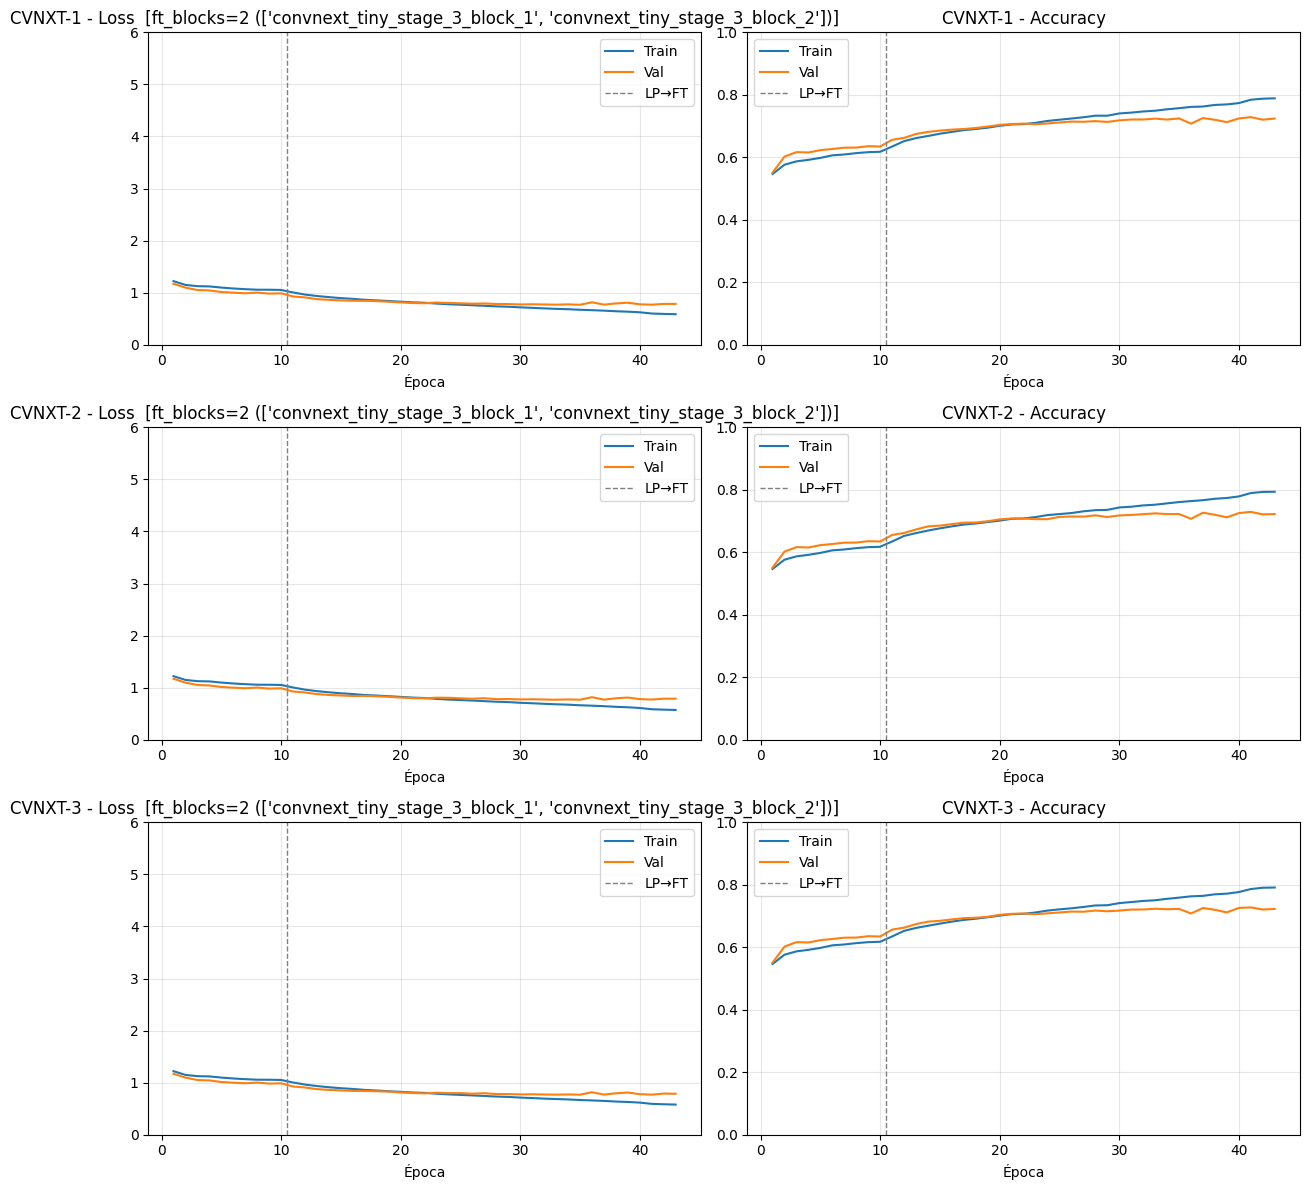

In [12]:
fig, axes = plt.subplots(len(CONFIGS), 2, figsize=(12, 4 * len(CONFIGS)))

for i, cfg in enumerate(CONFIGS):
    run_id   = cfg['run_id']
    h_lp     = HISTORIES_LP[run_id]
    h_ft     = HISTORIES_FT[run_id]
    boundary = len(h_lp['loss'])

    train_loss = h_lp['loss']     + h_ft['loss']
    val_loss   = h_lp['val_loss'] + h_ft['val_loss']
    train_acc  = h_lp['accuracy']     + h_ft['accuracy']
    val_acc    = h_lp['val_accuracy'] + h_ft['val_accuracy']
    epochs     = range(1, len(train_loss) + 1)

    ft_label = f'ft_blocks={cfg["ft_blocks"]} ({FINE_TUNE_BLOCKS[cfg["ft_blocks"]]})'

    axes[i, 0].plot(epochs, train_loss, label='Train')
    axes[i, 0].plot(epochs, val_loss,   label='Val')
    axes[i, 0].axvline(boundary + 0.5, color='gray', linestyle='--', linewidth=1, label='LP→FT')
    axes[i, 0].set_title(f'{run_id} - Loss  [{ft_label}]')
    axes[i, 0].set_xlabel('Época')
    axes[i, 0].set_ylim(0, 6)
    axes[i, 0].legend()
    axes[i, 0].grid(True, alpha=0.3)

    axes[i, 1].plot(epochs, train_acc, label='Train')
    axes[i, 1].plot(epochs, val_acc,   label='Val')
    axes[i, 1].axvline(boundary + 0.5, color='gray', linestyle='--', linewidth=1, label='LP→FT')
    axes[i, 1].set_title(f'{run_id} - Accuracy')
    axes[i, 1].set_xlabel('Época')
    axes[i, 1].set_ylim(0, 1)
    axes[i, 1].legend()
    axes[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### **Evaluación en Test**

In [13]:
# --- Evaluación en test ---
y_true = np.concatenate([y for x, y in test_data], axis=0)

EVAL = {}
for cfg in CONFIGS:
    run_id = cfg['run_id']
    model  = tf.keras.models.load_model(MODELS_PATH / f'{run_id}.keras')

    y_pred              = np.argmax(model.predict(test_data, verbose=0), axis=1)
    test_loss, test_acc = model.evaluate(test_data, verbose=0)

    report_row = log_results(run_id, y_true, y_pred, HISTORIES_FT[run_id], test_loss, test_acc, CLASSES)
    EVAL[run_id] = {
        'y_pred':     y_pred,
        'report':     classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True),
        'report_row': report_row,
    }
    del model
    gc.collect()

  CVNXT_results.csv actualizado - CVNXT-1
  CVNXT_results.csv actualizado - CVNXT-2
  CVNXT_results.csv actualizado - CVNXT-3


#### **Matrices de Confusión**

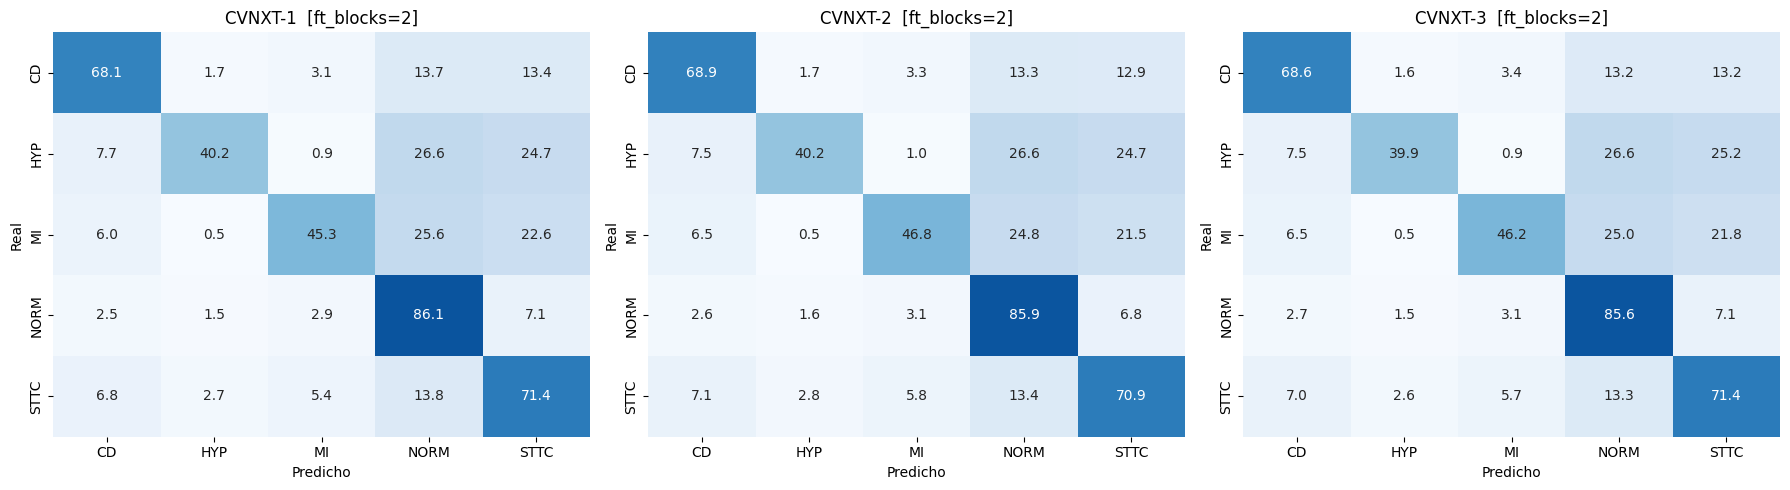

In [14]:
fig, axes = plt.subplots(1, len(CONFIGS), figsize=(6 * len(CONFIGS), 5))

for i, cfg in enumerate(CONFIGS):
    run_id  = cfg['run_id']
    cm_norm = confusion_matrix(y_true, EVAL[run_id]['y_pred'], normalize='true') * 100
    sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES,
                vmin=0, vmax=100, ax=axes[i], cbar=False)
    axes[i].set_xlabel('Predicho')
    axes[i].set_ylabel('Real')
    axes[i].set_title(f'{run_id}  [ft_blocks={cfg["ft_blocks"]}]')

plt.tight_layout()
plt.show()

#### **Tablas de Métricas**

In [15]:
for cfg in CONFIGS:
    run_id    = cfg['run_id']
    df_report = pd.DataFrame(EVAL[run_id]['report']).transpose()
    print(f'\n{run_id}  [ft_blocks={cfg["ft_blocks"]}]')
    display(df_report.style.format({
        'precision': '{:.3f}',
        'recall':    '{:.3f}',
        'f1-score':  '{:.3f}',
        'support':   '{:.0f}',
    }))


CVNXT-1  [ft_blocks=2]


,precision,recall,f1-score,support
CD,0.756,0.681,0.717,1814
HYP,0.571,0.402,0.472,572
MI,0.579,0.453,0.509,1006
NORM,0.763,0.861,0.809,3954
STTC,0.700,0.714,0.707,2912
accuracy,0.722,0.722,0.722,1
macro avg,0.674,0.622,0.643,10258
weighted avg,0.715,0.722,0.715,10258



CVNXT-2  [ft_blocks=2]


,precision,recall,f1-score,support
CD,0.749,0.689,0.718,1814
HYP,0.561,0.402,0.468,572
MI,0.569,0.468,0.514,1006
NORM,0.767,0.859,0.810,3954
STTC,0.706,0.709,0.708,2912
accuracy,0.722,0.722,0.722,1
macro avg,0.670,0.625,0.643,10258
weighted avg,0.716,0.722,0.716,10258



CVNXT-3  [ft_blocks=2]


,precision,recall,f1-score,support
CD,0.748,0.686,0.716,1814
HYP,0.571,0.399,0.470,572
MI,0.569,0.462,0.510,1006
NORM,0.767,0.856,0.809,3954
STTC,0.702,0.714,0.708,2912
accuracy,0.721,0.721,0.721,1
macro avg,0.671,0.623,0.642,10258
weighted avg,0.715,0.721,0.715,10258


In [16]:
# --- Tabla comparativa ---
comp_rows = []
for cfg in CONFIGS:
    run_id = cfg['run_id']
    row    = EVAL[run_id]['report_row']
    comp   = {
        'run_id':       run_id,
        'ft_blocks':    cfg['ft_blocks'],
        'balanced_acc': row['balanced_acc'],
        'macro_f1':     row['macro_f1'],
    }
    for cls in CLASSES:
        comp[f'f1_{cls}'] = row[f'f1_{cls}']
    comp_rows.append(comp)

df_comp = pd.DataFrame(comp_rows).set_index('run_id')
display(df_comp.style.format({col: '{:.4f}' for col in df_comp.select_dtypes('float').columns}))

,ft_blocks,balanced_acc,macro_f1,f1_CD,f1_HYP,f1_MI,f1_NORM,f1_STTC
run_id,,,,,,,,
CVNXT-1,2,0.6224,0.6426,0.7167,0.4718,0.5086,0.8090,0.7070
CVNXT-2,2,0.6253,0.6435,0.7176,0.4684,0.5136,0.8101,0.7076
CVNXT-3,2,0.6233,0.6424,0.7156,0.4696,0.5101,0.8088,0.7077
